# 03 · Distribution of average glucose

**Track 2 · Action items E1–E3 · Grading criterion 3 (Distributional modeling evidence, 15 marks)**

Goal: model `avg_glucose_level` with a probability distribution that is justified by how the data are generated, show evidence a skeptic can check that the fit is adequate, and say where it breaks and what that means for the rest of the analysis.

Background: [knowledge_base/07_distribution_fitting.md](../knowledge_base/07_distribution_fitting.md)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.mixture import GaussianMixture

from src.config import SEED, N_GOF_BOOT, FIGURES, TABLES
from src.data import load_raw
from src.stats_utils import wilson_ci, risk_ratio, fmt_ci

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)

df = load_raw()
x = df["avg_glucose_level"].to_numpy()
n = len(x)
print(f"n = {n}, seed = {SEED}, parametric-bootstrap replicates = {N_GOF_BOOT}")
pd.Series(x, name="avg_glucose_level").describe().round(2)

n = 5110, seed = 42, parametric-bootstrap replicates = 1000


count    5110.00
mean      106.15
std        45.28
min        55.12
25%        77.24
50%        91.88
75%       114.09
max       271.74
Name: avg_glucose_level, dtype: float64

## E1 · Which distributions, and why (decided before fitting)

1. **Glucose is a strictly positive concentration.** A Normal model puts probability on negative values and is symmetric, so it is included only as a reference.
2. **Log-normal.** Blood glucose is set by processes that act multiplicatively (insulin secretion and sensitivity, hepatic glucose output, absorption scale each other rather than add). A product of many positive factors is approximately log-normal by the central limit theorem on the log scale. Log-normal is the standard model for biomarker concentrations.
3. **Gamma.** The other common family for positive, right-skewed measurements. It has a lighter right tail than the log-normal, so comparing the two tells us about the tail.
4. **Two-component log-normal mixture.** The patients are a mix of people with normal glucose regulation and people with (diagnosed or undiagnosed) diabetes, whose glucose sits at a much higher level. If that mechanism is right, we expect, *before looking at the fit*:
   - a high component centred well above the diabetes range (random glucose ≥ 200 mg/dL is a diagnostic criterion),
   - a high-component weight of roughly 10–15%, similar to adult diabetes prevalence,
   - a higher stroke rate in the high component, since diabetes is a stroke risk factor.

Limitation: the dataset does not say whether `avg_glucose_level` is fasting, random or an average of several readings, nor its units (the values match mg/dL).

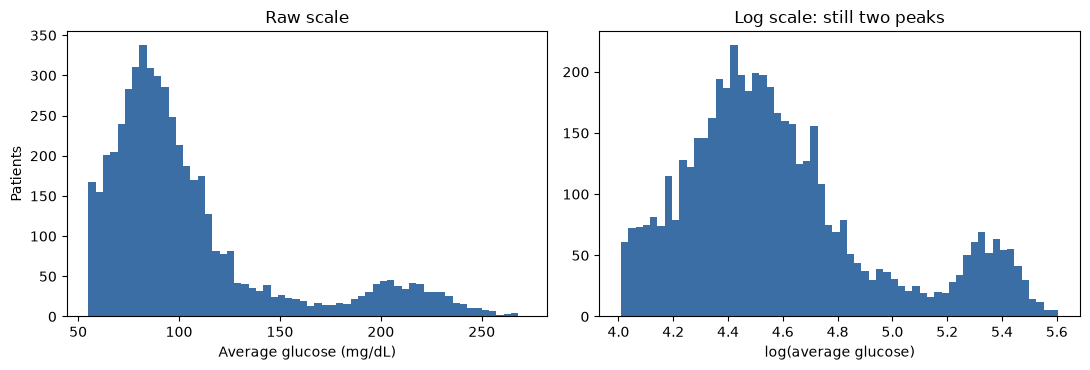

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(x, bins=60, color="#3b6ea5")
ax[0].set(xlabel="Average glucose (mg/dL)", ylabel="Patients", title="Raw scale")
ax[1].hist(np.log(x), bins=60, color="#3b6ea5")
ax[1].set(xlabel="log(average glucose)", title="Log scale: still two peaks")
plt.tight_layout()
plt.savefig(FIGURES / "glucose_histograms.png", dpi=150)
plt.show()

## E2 · Fit by maximum likelihood

Each model exposes the same interface (`fit`, `logpdf`, `cdf`, `sample`) so the goodness-of-fit code below treats them identically. Log-normal and Gamma have their location fixed at 0 (a concentration has a natural zero). The mixture is fitted as a 2-component Gaussian mixture on log(glucose), which is a log-normal mixture on the original scale.

In [3]:
class Normal:
    name, k = "Normal", 2
    def fit(self, v): return stats.norm.fit(v)
    def logpdf(self, v, p): return stats.norm.logpdf(v, *p)
    def cdf(self, v, p): return stats.norm.cdf(v, *p)
    def sample(self, p, size, rng): return stats.norm.rvs(*p, size=size, random_state=rng)

class LogNormal:
    name, k = "Log-normal", 2
    def fit(self, v): return stats.lognorm.fit(v, floc=0)
    def logpdf(self, v, p): return stats.lognorm.logpdf(v, *p)
    def cdf(self, v, p): return stats.lognorm.cdf(v, *p)
    def sample(self, p, size, rng): return stats.lognorm.rvs(*p, size=size, random_state=rng)

class Gamma:
    name, k = "Gamma", 2
    def fit(self, v): return stats.gamma.fit(v, floc=0)
    def logpdf(self, v, p): return stats.gamma.logpdf(v, *p)
    def cdf(self, v, p): return stats.gamma.cdf(v, *p)
    def sample(self, p, size, rng): return stats.gamma.rvs(*p, size=size, random_state=rng)

class LogNormalMixture:
    # p = (weights, means, sds) on the log scale
    def __init__(self, n_components=2):
        self.m = n_components
        self.name = f"Log-normal mixture ({n_components})"
        self.k = 3 * n_components - 1
    def fit(self, v, init=None):
        gm = GaussianMixture(self.m, random_state=SEED,
                             n_init=1 if init is not None else 10,
                             means_init=None if init is None else init[1].reshape(-1, 1))
        gm.fit(np.log(v).reshape(-1, 1))
        order = np.argsort(gm.means_.ravel())
        return (gm.weights_[order], gm.means_.ravel()[order], np.sqrt(gm.covariances_.ravel()[order]))
    def logpdf(self, v, p):
        w, mu, sd = p
        lv = np.log(v)[:, None]
        comp = np.log(w) + stats.norm.logpdf(lv, mu, sd)
        return np.logaddexp.reduce(comp, axis=1) - np.log(v)
    def cdf(self, v, p):
        w, mu, sd = p
        return (w * stats.norm.cdf((np.log(v)[:, None] - mu) / sd)).sum(axis=1)
    def sample(self, p, size, rng):
        w, mu, sd = p
        comp = rng.choice(len(w), size=size, p=w)
        return np.exp(rng.normal(mu[comp], sd[comp]))
    def posterior(self, v, p):
        w, mu, sd = p
        comp = np.log(w) + stats.norm.logpdf(np.log(v)[:, None], mu, sd)
        return np.exp(comp - np.logaddexp.reduce(comp, axis=1, keepdims=True))

models = [Normal(), LogNormal(), Gamma(), LogNormalMixture(2)]
params = {m.name: m.fit(x) for m in models}
# 3-component mixture: not motivated in advance; fitted only to check whether 2 is enough
mix3 = LogNormalMixture(3)
params[mix3.name] = mix3.fit(x)

rows = []
for m in models + [mix3]:
    ll = m.logpdf(x, params[m.name]).sum()
    rows.append({"model": m.name, "parameters": m.k, "log_lik": ll,
                 "AIC": -2 * ll + 2 * m.k, "BIC": -2 * ll + m.k * np.log(n)})
comparison = pd.DataFrame(rows)
comparison["dBIC_vs_best"] = comparison["BIC"] - comparison["BIC"].min()
comparison.round(1)

,model,parameters,log_lik,AIC,BIC,dBIC_vs_best
0,Normal,2,-26734.4,53472.8,53485.9,4043.3
1,Log-normal,2,-25525.2,51054.5,51067.5,1624.9
2,Gamma,2,-25840.7,51685.3,51698.4,2255.8
3,Log-normal mixture (2),5,-24701.8,49413.7,49446.4,3.7
4,Log-normal mixture (3),8,-24687.1,49390.3,49442.6,0.0


In [4]:
mix = models[3]
w, mu, sd = params[mix.name]
mix_table = pd.DataFrame({
    "component": ["low", "high"],
    "weight": w,
    "median_mg_dL": np.exp(mu),
    "log_sd": sd,
    "mean_mg_dL": np.exp(mu + sd**2 / 2),
})
mix_table.round(3)

,component,weight,median_mg_dL,log_sd,mean_mg_dL
0,low,0.868,88.282,0.232,90.697
1,high,0.132,205.722,0.123,207.281


## E2 · Evidence of fit

**Q–Q plots.** Points on the diagonal mean the model's quantiles match the data's.

**Formal tests.** The standard KS test assumes the parameters are known in advance. Ours are estimated from the same data, which makes the plain KS p-value far too large. We therefore use a **parametric bootstrap**: simulate n = 5,110 values from the fitted model, refit, and recompute the statistic, B times. The p-value is the share of simulated statistics at least as large as the observed one. We report Kolmogorov–Smirnov D (largest CDF gap; easy to interpret) and Anderson–Darling A² (more weight on the tails).

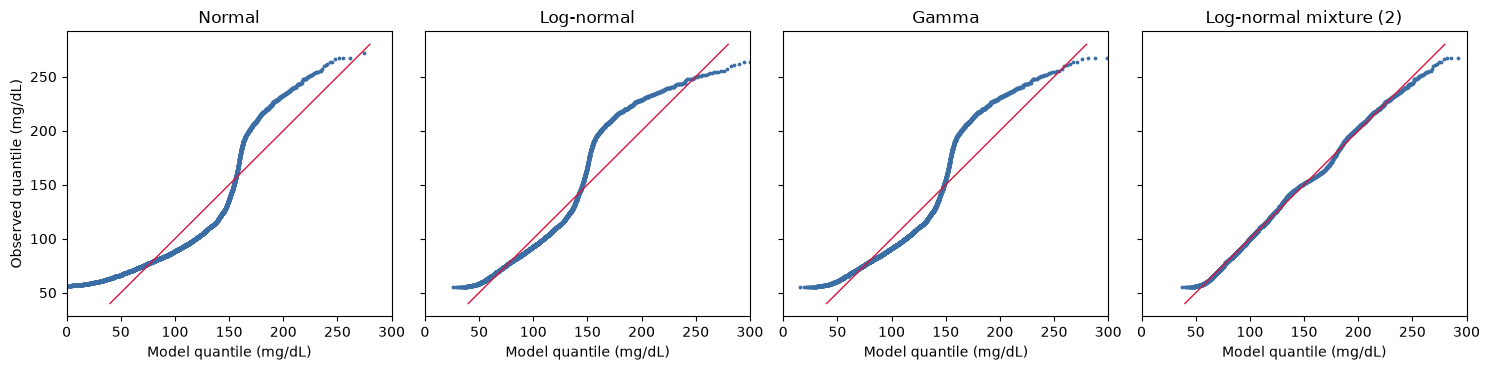

In [5]:
grid = np.linspace(1, 400, 40_000)
def quantiles(m, p, probs):
    if hasattr(m, "posterior"):  # mixture: invert the CDF numerically
        return np.interp(probs, m.cdf(grid, p), grid)
    dist = {"Normal": stats.norm, "Log-normal": stats.lognorm, "Gamma": stats.gamma}[m.name]
    return dist.ppf(probs, *p)

probs = (np.arange(1, n + 1) - 0.5) / n
xs = np.sort(x)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, m in zip(axes, models):
    q = quantiles(m, params[m.name], probs)
    ax.scatter(q, xs, s=3, color="#3b6ea5")
    ax.plot([40, 280], [40, 280], color="crimson", lw=1)
    ax.set(title=m.name, xlabel="Model quantile (mg/dL)", xlim=(0, 300))
axes[0].set_ylabel("Observed quantile (mg/dL)")
plt.tight_layout()
plt.savefig(FIGURES / "glucose_qq.png", dpi=150)
plt.show()

In [6]:
def ks_stat(u):
    u = np.sort(u); i = np.arange(1, len(u) + 1)
    return max((i / len(u) - u).max(), (u - (i - 1) / len(u)).max())

def ad_stat(u):
    u = np.clip(np.sort(u), 1e-12, 1 - 1e-12); m = len(u); i = np.arange(1, m + 1)
    return -m - np.mean((2 * i - 1) * (np.log(u) + np.log(1 - u[::-1])))

def param_boot_gof(model, p_hat, B, rng):
    u = model.cdf(x, p_hat)
    d_obs, a_obs = ks_stat(u), ad_stat(u)
    d_sim, a_sim = np.empty(B), np.empty(B)
    for b in range(B):
        xb = model.sample(p_hat, n, rng)
        pb = model.fit(xb, init=p_hat) if hasattr(model, "posterior") else model.fit(xb)
        ub = model.cdf(xb, pb)
        d_sim[b], a_sim[b] = ks_stat(ub), ad_stat(ub)
    return {"model": model.name, "KS_D": d_obs,
            "KS_p": (1 + (d_sim >= d_obs).sum()) / (B + 1),
            "KS_D_95pct_under_H0": np.quantile(d_sim, 0.95),
            "AD_A2": a_obs, "AD_p": (1 + (a_sim >= a_obs).sum()) / (B + 1),
            "AD_A2_95pct_under_H0": np.quantile(a_sim, 0.95)}

gof = pd.DataFrame([param_boot_gof(m, params[m.name], N_GOF_BOOT, rng) for m in models])
gof.round(4)

,model,KS_D,KS_p,KS_D_95pct_under_H0,AD_A2,AD_p,AD_A2_95pct_under_H0
0,Normal,0.1828,0.001,0.0127,352.0934,0.001,0.7182
1,Log-normal,0.1028,0.001,0.0128,125.1379,0.001,0.7774
2,Gamma,0.1314,0.001,0.0128,192.1167,0.001,0.7755
3,Log-normal mixture (2),0.0187,0.001,0.0118,3.0131,0.001,0.5518


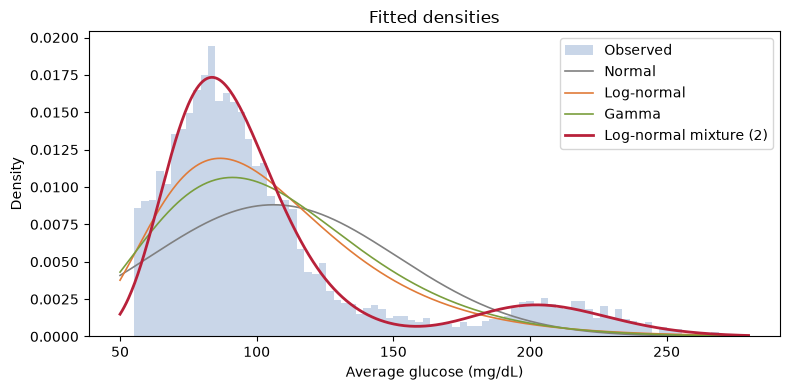

In [7]:
fit_summary = comparison.merge(gof, on="model", how="left")
fit_summary.to_csv(TABLES / "glucose_fit_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(x, bins=80, density=True, color="#c9d6e8", label="Observed")
xx = np.linspace(50, 280, 600)
for m, c in zip(models, ["grey", "#e07b39", "#7a9e3d", "#b8213a"]):
    ax.plot(xx, np.exp(m.logpdf(xx, params[m.name])), color=c, lw=2 if m is mix else 1.2, label=m.name)
ax.set(xlabel="Average glucose (mg/dL)", ylabel="Density", title="Fitted densities")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "glucose_fits.png", dpi=150)
plt.show()

### Where in the range does each model miss?

Observed vs expected patient counts by glucose band. Pearson residual = (observed − expected) / √expected; values beyond about ±2 mark bands the model gets wrong.

In [8]:
edges = np.array([0, 70, 80, 90, 100, 110, 125, 150, 175, 200, 225, 250, 400])
obs, _ = np.histogram(x, edges)
band = [f"{a}–{b}" if b < 400 else f"{a}+" for a, b in zip(edges[:-1], edges[1:])]
band[0] = "<70"
resid = pd.DataFrame({"band_mg_dL": band, "observed": obs})
for m in models[1:]:
    expected = n * np.diff(m.cdf(edges.astype(float).clip(1e-9), params[m.name]))
    resid[f"expected_{m.name}"] = expected.round(0)
    resid[f"resid_{m.name}"] = ((obs - expected) / np.sqrt(expected)).round(1)
resid.to_csv(TABLES / "glucose_fit_residuals_by_band.csv", index=False)
resid

,band_mg_dL,observed,expected_Log-normal,resid_Log-normal,expected_Gamma,resid_Gamma,expected_Log-normal mixture (2),resid_Log-normal mixture (2)
0,<70,754,874.0,-4.0,933.0,-5.9,705.0,1.8
1,70–80,776,560.0,9.1,486.0,13.1,784.0,-0.3
2,80–90,872,606.0,10.8,534.0,14.6,875.0,-0.1
3,90–100,729,588.0,5.8,539.0,8.2,759.0,-1.1
4,100–110,506,528.0,-1.0,509.0,-0.1,549.0,-1.9
5,110–125,473,641.0,-6.6,657.0,-7.2,464.0,0.4
6,125–150,269,681.0,-15.8,756.0,-17.7,252.0,1.1
7,150–175,128,343.0,-11.6,399.0,-13.6,103.0,2.5
8,175–200,169,160.0,0.7,181.0,-0.9,219.0,-3.4
9,200–225,270,72.0,23.3,74.0,22.8,243.0,1.8


## E3 · Does the mixture mean something? Link to stroke

If the high component is a diabetic sub-population, it should carry a higher stroke risk. We assign each patient to the component with the larger posterior probability and compare stroke rates (Wilson CIs; risk ratio with a log-scale CI).

This is a check of the data-generating story, not a pre-registered hypothesis test (the hypotheses live in [docs/hypotheses.md](../docs/hypotheses.md)).

In [9]:
post_high = mix.posterior(x, params[mix.name])[:, 1]
high = post_high > 0.5
cutoff = grid[np.argmin(np.abs(mix.posterior(grid, params[mix.name])[:, 1] - 0.5))]
print(f"Patients are assigned to the high component above {cutoff:.0f} mg/dL")

y = df["stroke"].to_numpy()
rows = []
for label, mask in [("low component", ~high), ("high component", high)]:
    p, lo, hi = wilson_ci(int(y[mask].sum()), int(mask.sum()))
    rows.append({"group": label, "patients": int(mask.sum()), "strokes": int(y[mask].sum()),
                 "stroke_rate_95CI": fmt_ci(p, lo, hi, digits=1, pct=True),
                 "hypertension_rate": df.loc[mask, "hypertension"].mean().round(3),
                 "median_age": df.loc[mask, "age"].median()})
by_comp = pd.DataFrame(rows)
rr = risk_ratio(int(y[high].sum()), int(high.sum()), int(y[~high].sum()), int((~high).sum()))
print("Stroke risk ratio, high vs low component:", fmt_ci(*rr))
by_comp.to_csv(TABLES / "glucose_component_stroke_rates.csv", index=False)
by_comp

Patients are assigned to the high component above 160 mg/dL
Stroke risk ratio, high vs low component: 3.70 (2.89 to 4.73)


,group,patients,strokes,stroke_rate_95CI,hypertension_rate,median_age
0,low component,4442,160,3.6% (3.1 to 4.2),0.075,42.0
1,high component,668,89,13.3% (11.0 to 16.1),0.250,61.0


## E3 · Where the fit breaks and what it means

*(Written after running. If the data or seed change, re-check these numbers against the tables above.)*

**1. A single log-normal or Gamma does not fit.** Both bend into an S-shape on the Q–Q plot. Their largest CDF gap is 10.3 (log-normal) and 13.1 (Gamma) percentage points. They predict about 100 patients in the 200–250 mg/dL band where 409 are observed (Pearson residuals above +18). They cannot produce the second peak, so any analysis that assumes glucose comes from one log-normal or Gamma population is built on a wrong model.

**2. The two-component mixture fits much better, and it matches the mechanism we predicted before fitting.** BIC drops by about 1,620 compared with the log-normal. The high component holds 13.2% of patients with a median of 206 mg/dL, which is in the diabetic range and close to the expected weight. Patients in it have a stroke rate of 13.3% vs 3.6% (risk ratio 3.70, 95% CI 2.89 to 4.73). They are also older (median 61 vs 42 years) and more often hypertensive (25% vs 7.5%). The data-generating story is therefore supported by evidence beyond the histogram.

**3. The mixture is still formally rejected, and we say so.** KS D = 0.019, against 0.012 expected under a correct model (parametric bootstrap p ≤ 0.001; A² = 3.0, also p ≤ 0.001). With n = 5,110 the test detects small departures. The largest CDF gap is 1.9 percentage points, about one-fifth of the log-normal's. The misfit sits in three places:
- **Lower floor:** no value is below 55.1 mg/dL, but the model expects a thin tail below that (flat start of the Q–Q plot). This looks like a measurement floor or a truncation in how the data were recorded.
- **Between the peaks (150–200 mg/dL):** too few patients predicted at 150–175 (residual +2.5) and too many at 175–200 (−3.4). The components are not exactly log-normal.
- **Upper ceiling:** no value is above 272 mg/dL, but the model expects 38 patients above 250 where 25 are observed (−2.1). This also suggests a recording cap.

A 3-component mixture has a slightly lower BIC (by 3.7, weak evidence). It was not motivated in advance, and its extra component only splits the low peak, so we keep the 2-component model and report the 3-component one here for transparency.

**What this means for the analyses that depend on it**
- **Hypothesis tests on glucose (Track 4):** the mean is a poor summary of a two-peaked variable. A difference in means between stroke and non-stroke patients mixes two things: a larger share of high-glucose patients, and a shift within each group. Report the mean difference with a bootstrap CI (valid without a distributional assumption), a rank-based effect size (Cliff's δ), and the difference in the share of patients above 160 mg/dL.
- **Logistic regression (Track 3, G3):** a straight-line effect of glucose on the log-odds is unlikely to hold when risk jumps between components. Check linearity with splines, or compare with a high-glucose indicator.
- **Coverage simulation (F2):** the fitted mixture is close enough to the data (1.9-point maximum CDF gap) to serve as the "true" population for checking interval coverage. The floor and ceiling misfits affect only the extreme tails, which matter little for means and proportions.
- **Wording:** "high-glucose component" is a statistical grouping, not a diabetes diagnosis. The data contain no diagnosis field.